In [1]:
import io
import zipfile
import requests
import numpy as np
import pandas as pd
import xarray as xr

# ==============================================================================
# 1. FETCH DR. GRAMS' OFFICIAL ERA5 WEATHER REGIME CATALOGUE (ZENODO / GITHUB)
# ==============================================================================
# Official dataset: Grams et al., "Year-round North Atlantic-European Weather 
# Regimes in ERA5 reanalyses" (Zenodo Record 17080146 / cmgrams/wr_data_package_era5)
ZENODO_ZIP_URL = "https://zenodo.org/records/17080146/files/wr_data_package_V1.0.zip?download=1"

REGIME_MAP = {
    0: "No_Regime",
    1: "AT",    # Atlantic Trough (Cyclonic)
    2: "ZO",    # Zonal Regime (Cyclonic)
    3: "ScTr",  # Scandinavian Trough (Cyclonic)
    4: "AR",    # Atlantic Ridge (Blocked)
    5: "EuBL",  # European Blocking (Blocked)
    6: "ScBL",  # Scandinavian Blocking (Blocked)
    7: "GL",    # Greenland Blocking (Blocked)
}

# Standard ordering from Grams et al. (cyclonic grouped first, blocked second)
REGIME_ORDER = ["AT", "ZO", "ScTr", "AR", "EuBL", "ScBL", "GL", "No_Regime"]

print("1. Downloading Dr. Grams' ERA5 Weather Regime catalogue from Zenodo...")
resp = requests.get(ZENODO_ZIP_URL, timeout=60)
resp.raise_for_status()

with zipfile.ZipFile(io.BytesIO(resp.content)) as z:
    # Locate WR_LCattribution.txt inside the zip archive
    lc_filename = [f for f in z.namelist() if f.endswith("WR_LCattribution.txt")][0]
    with z.open(lc_filename) as f:
        lines = [line.decode("utf-8", errors="ignore").strip() for line in f]

# Parse lines starting with an integer (hour since 1979-01-01)
# Columns: [0] hour | [1] yyyymmdd_hh | [2] eof | [3] max_IWR | [4] LC_attribution
records = []
for line in lines:
    parts = line.split()
    if len(parts) == 5 and (parts[0].lstrip("-").isdigit()):
        records.append((parts[1], int(parts[4])))

wr_3h = pd.DataFrame(records, columns=["datetime_str", "wr_id"])
wr_3h["time"] = pd.to_datetime(wr_3h["datetime_str"], format="%Y%m%d_%H")
wr_3h["date"] = wr_3h["time"].dt.floor("D")

# Aggregate 3-hourly life-cycle attributions to daily dominant regime (daily mode)
daily_wr = (
    wr_3h.groupby("date")["wr_id"]
    .agg(lambda x: x.mode().iloc[0])
    .to_frame()
)
daily_wr["regime"] = daily_wr["wr_id"].map(REGIME_MAP)
print(f"   -> Loaded {len(daily_wr):,} days of ERA5 regimes ({daily_wr.index.min().date()} to {daily_wr.index.max().date()}).")

1. Downloading Dr. Grams' ERA5 Weather Regime catalogue from Zenodo...
   -> Loaded 27,591 days of ERA5 regimes (1950-01-11 to 2025-07-26).


In [16]:
# ==============================================================================
# 2. FETCH METEOSWISS OPEN DATA FOR ZÜRICH / FLUNTERN (STATION 'SMA')
# ==============================================================================
print("2. Downloading MeteoSwiss SwissMetNet daily series for Zürich (SMA)...")

# 'ogd-smn' contains both temperature (tre200d0, tre200dx) and precipitation (rre150d0)
URLS_TO_TRY = [
    "https://data.geo.admin.ch/ch.meteoschweiz.ogd-smn/sma/ogd-smn_sma_d_historical.csv",
    "https://data.geo.admin.ch/ch.meteoschweiz.ogd-smn/sma/ogd-smn_sma_d_recent.csv",
]

dfs_ch = []
for url in URLS_TO_TRY:
    r = requests.get(url, timeout=30)
    r.raise_for_status()
    dfs_ch.append(pd.read_csv(io.StringIO(r.text), sep=";"))

raw_ch = pd.concat(dfs_ch, ignore_index=True)

# Parse MeteoSwiss OGD timestamp ('dd.mm.YYYY HH:MM')
raw_ch["date"] = pd.to_datetime(raw_ch["reference_timestamp"], format="%d.%m.%Y %H:%M")
raw_ch = raw_ch.drop_duplicates(subset=["date"]).set_index("date").sort_index()

ch_obs = pd.DataFrame(index=raw_ch.index)
ch_obs["t2m_mean"] = pd.to_numeric(raw_ch["tre200d0"], errors="coerce")
ch_obs["t2m_max"]  = pd.to_numeric(raw_ch["tre200dx"], errors="coerce")
ch_obs["precip"]   = pd.to_numeric(raw_ch["rre150d0"], errors="coerce")
ch_obs = ch_obs.dropna()
print(f"   -> Loaded {len(ch_obs):,} complete days of Zürich temperature & precipitation.")

2. Downloading MeteoSwiss SwissMetNet daily series for Zürich (SMA)...
   -> Loaded 52,740 complete days of Zürich temperature & precipitation.


In [19]:
# ==============================================================================
# 3. XARRAY PIPELINE: SEASONAL ANOMALIES & MERGING (1979–2024 STANDARD ERA5)
# ==============================================================================
print("3. Computing seasonal anomalies in xarray and merging with regimes...")

ds = xr.Dataset.from_dataframe(ch_obs.loc["1979-01-01":"2024-12-31"])

# Compute daily climatology (1991-2020 WMO standard reference period) and anomalies
clim_t2m = ds["t2m_max"].sel(date=slice("1991-01-01", "2020-12-31")).groupby("date.dayofyear").mean("date")
ds["t2m_max_anom"] = ds["t2m_max"].groupby("date.dayofyear") - clim_t2m

# Merge weather regime labels into the xarray Dataset
ds["regime"] = ("date", daily_wr.reindex(ds.indexes["date"])["regime"].values)

# Convert to DataFrame and filter valid rows
df = ds.to_dataframe().dropna(subset=["regime", "t2m_max_anom", "precip"])
df["season"] = df.index.month.map(
    lambda m: "DJF (Winter)" if m in [12, 1, 2]
    else ("JJA (Summer)" if m in [6, 7, 8] else "Transition")
)

3. Computing seasonal anomalies in xarray and merging with regimes...


In [20]:
# ==============================================================================
# 4. COMPUTE CONDITIONAL RISK RATIOS FOR EXTREMES BY REGIME
# ==============================================================================
def compute_regime_risk_ratios(sub_df, label):
    t95 = sub_df["t2m_max_anom"].quantile(0.95)
    t05 = sub_df["t2m_max_anom"].quantile(0.05)
    p95 = sub_df["precip"].quantile(0.95)

    sub_df = sub_df.copy()
    sub_df["warm_ext"] = (sub_df["t2m_max_anom"] >= t95).astype(float)
    sub_df["cold_ext"] = (sub_df["t2m_max_anom"] <= t05).astype(float)
    sub_df["wet_ext"]  = (sub_df["precip"] >= p95).astype(float)

    grp = sub_df.groupby("regime")
    stats = pd.DataFrame({
        "Days": grp["t2m_max"].count(),
        "Freq_Pct": grp["t2m_max"].count() * 100.0 / len(sub_df),
        "Mean_Tmax_Anom_C": grp["t2m_max_anom"].mean(),
        "Warm_95_RiskRatio": grp["warm_ext"].mean() / 0.05,
        "Cold_05_RiskRatio": grp["cold_ext"].mean() / 0.05,
        "Wet_95_RiskRatio": grp["wet_ext"].mean() / 0.05,
    })
    stats = stats.reindex([r for r in REGIME_ORDER if r in stats.index])
    print(f"\n{'='*78}")
    print(f" {label} | Thresholds: Tmax_anom p95={t95:+.1f}°C, p05={t05:+.1f}°C | Precip p95={p95:.1f} mm/d")
    print(f"{'='*78}")
    print(stats.round(2).to_string())

compute_regime_risk_ratios(df, "YEAR-ROUND (1979–2024) — ZÜRICH (SMA)")
compute_regime_risk_ratios(df[df["season"] == "JJA (Summer)"], "SUMMER (JJA, 1979–2024) — ZÜRICH (SMA)")
compute_regime_risk_ratios(df[df["season"] == "DJF (Winter)"], "WINTER (DJF, 1979–2024) — ZÜRICH (SMA)")


 YEAR-ROUND (1979–2024) — ZÜRICH (SMA) | Thresholds: Tmax_anom p95=+7.3°C, p05=-7.8°C | Precip p95=15.9 mm/d
           Days  Freq_Pct  Mean_Tmax_Anom_C  Warm_95_RiskRatio  Cold_05_RiskRatio  Wet_95_RiskRatio
regime                                                                                             
AT         1567      9.33              1.91               2.08               0.27              1.38
ZO         1557      9.27              2.20               1.94               0.28              0.60
ScTr       1742     10.37             -0.68               0.63               1.11              1.26
AR         1546      9.20             -2.50               0.25               1.80              0.67
EuBL       1681     10.00             -0.60               0.68               1.07              0.70
ScBL       1841     10.96             -0.03               1.00               0.88              0.78
GL         1703     10.14             -1.06               0.52               1.63         

5. Generating seasonal weather regime comparison plot...


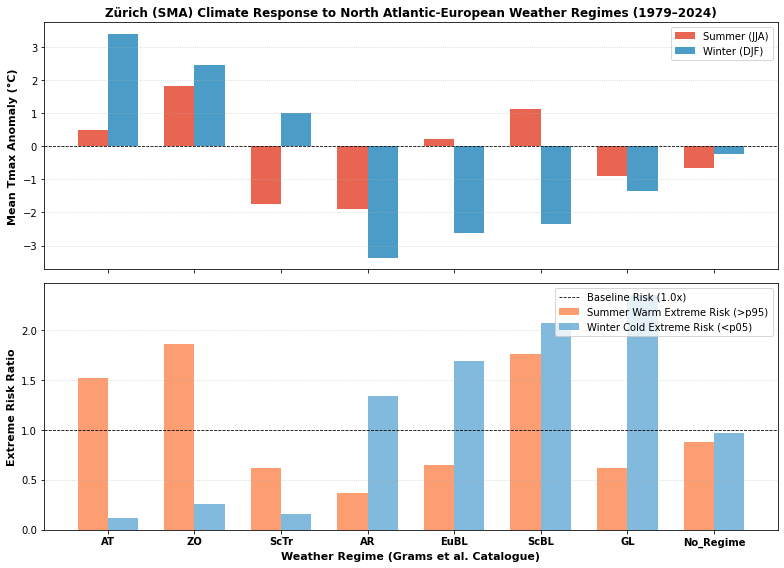

In [21]:
import matplotlib.pyplot as plt
import numpy as np

# ==============================================================================
# 5. VISUALIZE SUMMER VS. WINTER REGIME IMPACTS
# ==============================================================================
print("5. Generating seasonal weather regime comparison plot...")

def get_regime_summary(subset):
    t95 = subset["t2m_max_anom"].quantile(0.95)
    t05 = subset["t2m_max_anom"].quantile(0.05)
    sub = subset.copy()
    sub["warm_ext"] = (sub["t2m_max_anom"] >= t95).astype(float)
    sub["cold_ext"] = (sub["t2m_max_anom"] <= t05).astype(float)
    
    grp = sub.groupby("regime")
    res = pd.DataFrame({
        "Mean_Tmax_Anom": grp["t2m_max_anom"].mean(),
        "Warm_RiskRatio": grp["warm_ext"].mean() / 0.05,
        "Cold_RiskRatio": grp["cold_ext"].mean() / 0.05,
    })
    return res.reindex(REGIME_ORDER)

jja_stats = get_regime_summary(df[df["season"] == "JJA (Summer)"])
djf_stats = get_regime_summary(df[df["season"] == "DJF (Winter)"])

fig, axes = plt.subplots(2, 1, figsize=(11, 8), sharex=True)
x = np.arange(len(REGIME_ORDER))
width = 0.35

# --- PANEL 1: Temperature Anomalies (°C) ---
axes[0].bar(x - width/2, jja_stats["Mean_Tmax_Anom"], width, label='Summer (JJA)', color='#e34a33', alpha=0.85)
axes[0].bar(x + width/2, djf_stats["Mean_Tmax_Anom"], width, label='Winter (DJF)', color='#2b8cbe', alpha=0.85)
axes[0].axhline(0, color='black', linewidth=0.8, linestyle='--')
axes[0].set_ylabel('Mean Tmax Anomaly (°C)', fontsize=11, fontweight='bold')
axes[0].set_title('Zürich (SMA) Climate Response to North Atlantic-European Weather Regimes (1979–2024)', fontsize=12, fontweight='bold')
axes[0].legend(frameon=True, loc='upper right')
axes[0].grid(axis='y', linestyle=':', alpha=0.6)

# --- PANEL 2: Extreme Risk Ratios (Warm in JJA, Cold in DJF) ---
axes[1].bar(x - width/2, jja_stats["Warm_RiskRatio"], width, label='Summer Warm Extreme Risk (>p95)', color='#fc8d59', alpha=0.85)
axes[1].bar(x + width/2, djf_stats["Cold_RiskRatio"], width, label='Winter Cold Extreme Risk (<p05)', color='#6baed6', alpha=0.85)
axes[1].axhline(1.0, color='black', linewidth=0.8, linestyle='--', label='Baseline Risk (1.0x)')
axes[1].set_ylabel('Extreme Risk Ratio', fontsize=11, fontweight='bold')
axes[1].set_xticks(x)
axes[1].set_xticklabels(REGIME_ORDER, fontsize=10, fontweight='bold')
axes[1].set_xlabel('Weather Regime (Grams et al. Catalogue)', fontsize=11, fontweight='bold')
axes[1].legend(frameon=True, loc='upper right')
axes[1].grid(axis='y', linestyle=':', alpha=0.6)

plt.tight_layout()
plt.show()